# Code templates: plotting and everyday helpers

Copy-paste functions for the things you write in every project. Each function is short, documented, and demonstrated right below its definition.

| Section | Functions |
|---|---|
| 0. Style | `set_style` |
| 1. Basic plots | `plot_line`, `plot_bar`, `plot_hist`, `plot_scatter`, `plot_box`, `plot_corr`, `plot_grid` |
| 2. Model diagnostics | `plot_pred_vs_actual`, `plot_residuals`, `plot_deciles`, `plot_importance`, `plot_roc_pr`, `plot_learning_curve`, `plot_cv_comparison` |
| 3. Time series | `plot_series` |
| 4. Helpers | `timer`, `seed_everything`, `split_3way`, `regression_metrics`, `classification_metrics`, `compare_models`, `save_model` / `load_model`, `savefig` |

Tip: copy the cells you need into a `utils.py` in your project and `from utils import *`.

## 0. Style
One call at the top of a notebook gives consistent, readable charts. The palette is colour-blind-friendly and ordered (use colours in order, never cycle past 8).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"

def set_style(figsize=(8, 4.5), font_size=10):
    # Clean matplotlib defaults: light grid, no top/right spines, fixed colour order.
    plt.rcParams.update({
        "figure.figsize": figsize, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "lines.linewidth": 2, "font.size": font_size, "legend.frameon": False,
    })

set_style()
rng = np.random.default_rng(0)

Demo data used below: a regression dataset (California housing) and a classification dataset (breast cancer).

In [2]:
from sklearn.datasets import fetch_california_housing, load_breast_cancer
house = fetch_california_housing(as_frame=True).frame.rename(columns={"MedHouseVal": "price"})
cancer_X, cancer_y = load_breast_cancer(return_X_y=True, as_frame=True)
house.head(3)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521


## 1. Basic plots

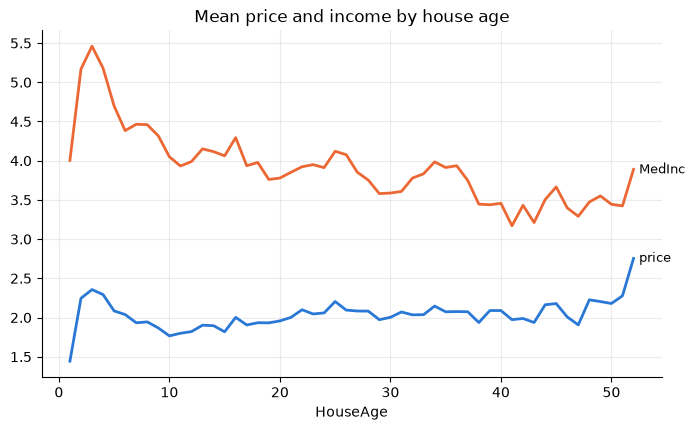

In [3]:
def plot_line(df, x, ys, title="", xlabel=None, ylabel=None, ax=None, label_ends=True):
    # One or more lines from a DataFrame. Labels each line at its end when there are only a few (<=4).
    ax = ax or plt.subplots()[1]
    ys = [ys] if isinstance(ys, str) else ys
    for i, y in enumerate(ys):
        ax.plot(df[x], df[y], color=PALETTE[i % len(PALETTE)], label=y)
        if label_ends and len(ys) <= 4:
            ax.annotate(y, (df[x].iloc[-1], df[y].iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    if len(ys) > 1 and not (label_ends and len(ys) <= 4): ax.legend()
    ax.set(title=title, xlabel=xlabel or x, ylabel=ylabel or (ys[0] if len(ys) == 1 else ""))
    return ax

by_age = house.groupby("HouseAge", as_index=False)[["price", "MedInc"]].mean()
plot_line(by_age, "HouseAge", ["price", "MedInc"], title="Mean price and income by house age");
plt.show()

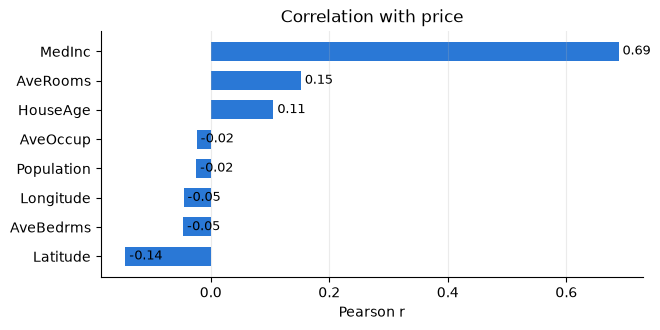

In [4]:
def plot_bar(values, title="", xlabel="", horizontal=True, sort=True, labels=True, color=None, ax=None, fmt="{:.2f}"):
    # Bar chart from a Series (index = categories). Horizontal + sorted is the most readable default.
    s = values.sort_values(ascending=horizontal) if sort else values
    ax = ax or plt.subplots(figsize=(7, max(2.5, 0.4 * len(s))) if horizontal else None)[1]
    color = color or PALETTE[0]
    if horizontal:
        ax.barh(s.index.astype(str), s.values, color=color, height=0.65); ax.grid(axis="y", visible=False); ax.set_xlabel(xlabel)
        if labels:
            for i, v in enumerate(s.values): ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    else:
        ax.bar(s.index.astype(str), s.values, color=color, width=0.65); ax.grid(axis="x", visible=False); ax.set_ylabel(xlabel)
        if labels:
            for i, v in enumerate(s.values): ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
    return ax

plot_bar(house.corr()["price"].drop("price"), title="Correlation with price", xlabel="Pearson r");
plt.show()

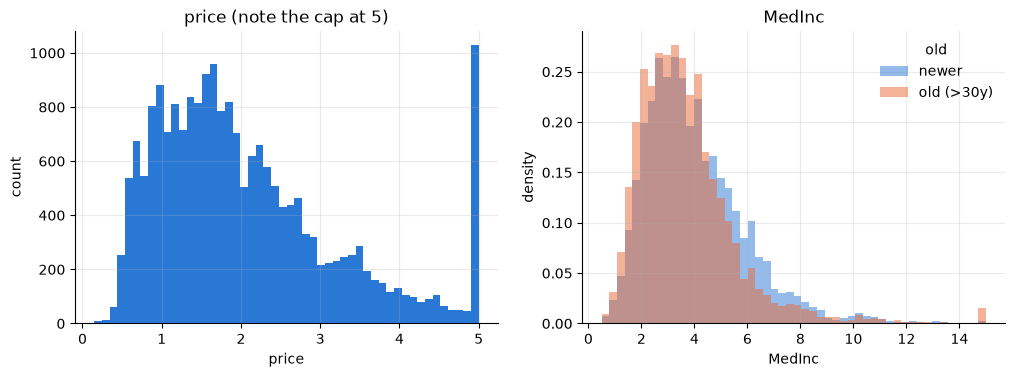

In [5]:
def plot_hist(data, col=None, by=None, bins=50, log=False, density=False, title="", ax=None):
    # Histogram of a Series / DataFrame column; `by` overlays one histogram per group (keep groups <= 4).
    ax = ax or plt.subplots()[1]
    s = data[col] if col else data
    if log: s = np.log1p(s.clip(lower=0))
    if by is None:
        ax.hist(s.dropna(), bins=bins, color=PALETTE[0], density=density)
    else:
        for i, (g, sub) in enumerate(s.groupby(data[by])):
            ax.hist(sub.dropna(), bins=bins, alpha=0.5, color=PALETTE[i], label=str(g), density=True)
        ax.legend(title=by)
    ax.set(title=title or (f"log1p({col})" if log else col), xlabel=("log1p " if log else "") + (col or ""), ylabel="density" if density or by else "count")
    return ax

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_hist(house, "price", ax=axes[0], title="price (note the cap at 5)")
plot_hist(house.assign(old=np.where(house.HouseAge > 30, "old (>30y)", "newer")), "MedInc", by="old", ax=axes[1]);
plt.show()

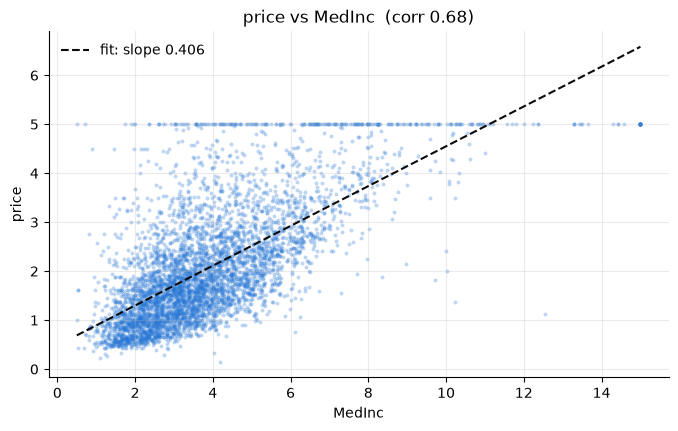

In [6]:
def plot_scatter(df, x, y, hue=None, fit=True, sample=5000, alpha=0.3, title="", ax=None):
    # Scatter with optional colour groups and a least-squares line. Samples big data so it stays readable.
    ax = ax or plt.subplots()[1]
    d = df.sample(min(sample, len(df)), random_state=0)
    if hue is None:
        ax.scatter(d[x], d[y], s=8, alpha=alpha, color=PALETTE[0], lw=0)
    else:
        for i, (g, sub) in enumerate(d.groupby(hue)):
            ax.scatter(sub[x], sub[y], s=8, alpha=alpha, color=PALETTE[i], lw=0, label=str(g))
        ax.legend(title=hue, markerscale=2)
    if fit:
        b, a = np.polyfit(d[x], d[y], 1)
        xs = np.linspace(d[x].min(), d[x].max(), 100)
        ax.plot(xs, a + b * xs, color="#0b0b0b", lw=1.5, ls="--", label=f"fit: slope {b:.3g}")
        ax.legend()
    ax.set(xlabel=x, ylabel=y, title=title or f"{y} vs {x}  (corr {d[x].corr(d[y]):.2f})")
    return ax

plot_scatter(house, "MedInc", "price");
plt.show()

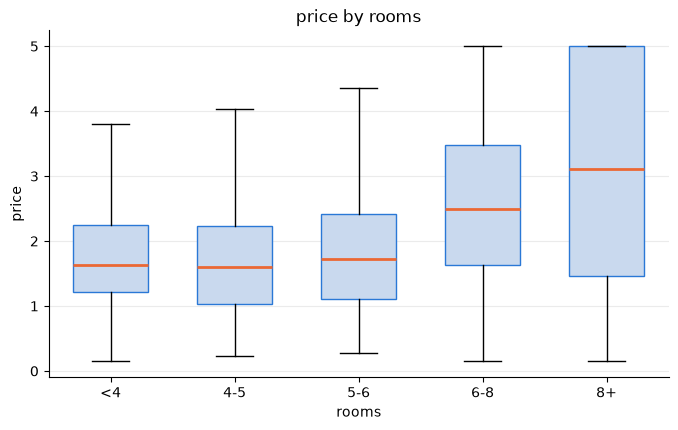

In [7]:
def plot_box(df, value, by, title="", order=None, ax=None):
    # Box plot of `value` for each group in `by` (median, quartiles, whiskers; outliers hidden for clarity).
    ax = ax or plt.subplots()[1]
    order = order or sorted(df[by].dropna().unique())
    data = [df.loc[df[by] == g, value].dropna() for g in order]
    bp = ax.boxplot(data, tick_labels=[str(g) for g in order], showfliers=False, patch_artist=True, widths=0.6)
    for patch in bp["boxes"]: patch.set(facecolor="#c9d9ee", edgecolor=PALETTE[0])
    for med in bp["medians"]: med.set(color=PALETTE[1], lw=2)
    ax.set(title=title or f"{value} by {by}", xlabel=by, ylabel=value); ax.grid(axis="x", visible=False)
    return ax

plot_box(house.assign(rooms=pd.cut(house.AveRooms, [0, 4, 5, 6, 8, 200], labels=["<4", "4-5", "5-6", "6-8", "8+"])), "price", "rooms",
         order=["<4", "4-5", "5-6", "6-8", "8+"]);
plt.show()

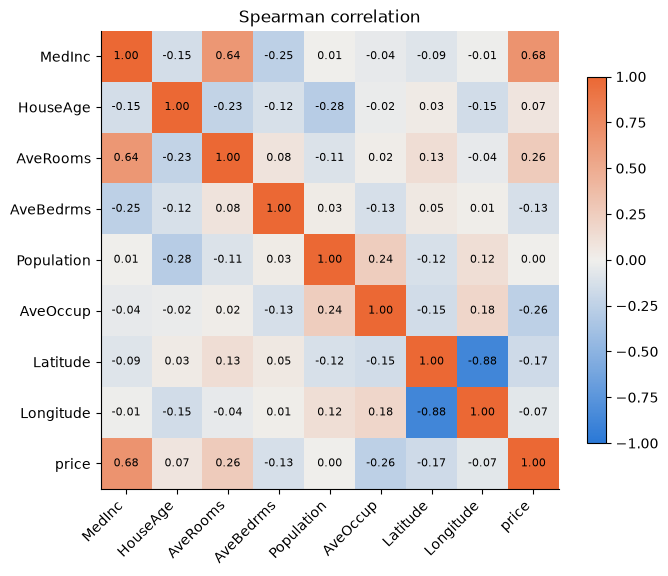

In [8]:
def plot_corr(df, method="spearman", annot=True, title="", ax=None):
    # Correlation heatmap with a diverging blue-grey-orange scale centred on 0.
    from matplotlib.colors import LinearSegmentedColormap
    c = df.select_dtypes("number").corr(method=method)
    cmap = LinearSegmentedColormap.from_list("div", [PALETTE[0], "#f0efec", PALETTE[1]])
    ax = ax or plt.subplots(figsize=(0.6 * len(c) + 2, 0.55 * len(c) + 1))[1]
    im = ax.imshow(c, cmap=cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right"); ax.set_yticks(range(len(c)), c.columns)
    if annot:
        for i in range(len(c)):
            for j in range(len(c)):
                ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.grid(False); ax.set_title(title or f"{method.title()} correlation")
    plt.colorbar(im, ax=ax, shrink=0.8)
    return ax

plot_corr(house);
plt.show()

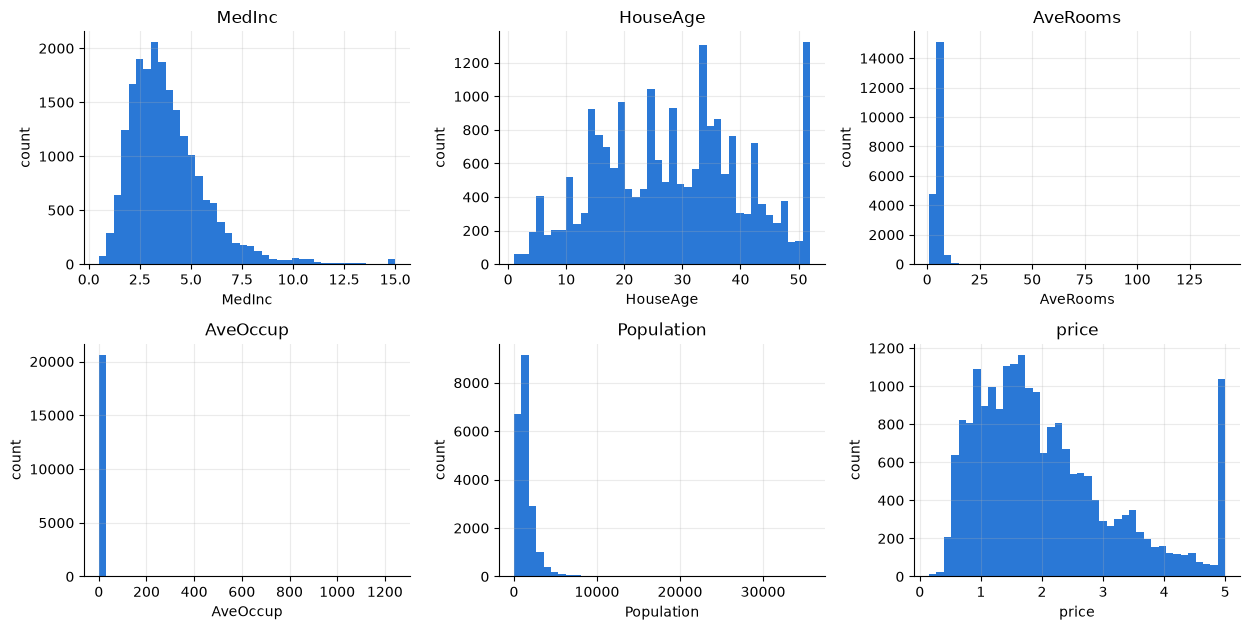

In [9]:
def plot_grid(df, cols, plot_fn, ncols=3, size=(4.2, 3.2), **kw):
    # Small multiples: call plot_fn(df, col, ax=ax, **kw) for each column on a grid of subplots.
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    for ax, c in zip(axes.ravel(), cols): plot_fn(df, c, ax=ax, **kw)
    for ax in axes.ravel()[len(cols):]: ax.axis("off")
    fig.tight_layout()
    return fig

plot_grid(house, ["MedInc", "HouseAge", "AveRooms", "AveOccup", "Population", "price"], plot_hist, bins=40);
plt.show()

## 2. Model diagnostics
Fit two quick models so the diagnostic plots have something to show.

In [10]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xh, yh = house.drop(columns="price"), house["price"]
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(Xh, yh, test_size=0.2, random_state=0)
reg = lgb.LGBMRegressor(n_estimators=500, learning_rate=0.05, verbose=-1).fit(Xh_tr, yh_tr)
pred_h = reg.predict(Xh_te)

Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(cancer_X, cancer_y, test_size=0.3, stratify=cancer_y, random_state=0)
clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)).fit(Xc_tr, yc_tr)
proba_c = clf.predict_proba(Xc_te)[:, 1]

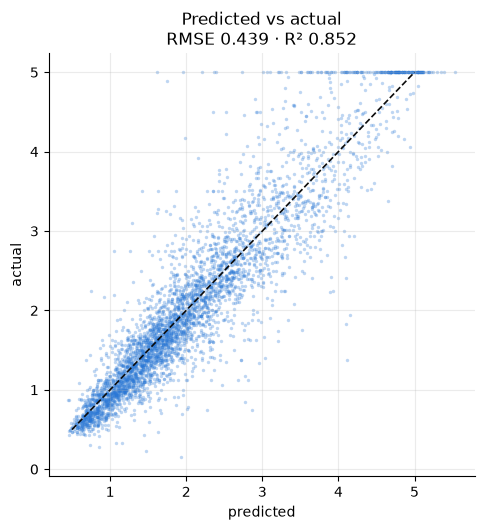

In [11]:
def plot_pred_vs_actual(y_true, y_pred, title="Predicted vs actual", sample=5000, ax=None):
    # Scatter of predictions against truth with the y = x line. Points above the line = under-prediction.
    ax = ax or plt.subplots(figsize=(5.5, 5.5))[1]
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    idx = rng.choice(len(y_true), min(sample, len(y_true)), replace=False)
    ax.scatter(y_pred[idx], y_true[idx], s=6, alpha=0.3, color=PALETTE[0], lw=0)
    lo, hi = np.percentile(np.r_[y_true, y_pred], [0.5, 99.5])
    ax.plot([lo, hi], [lo, hi], color="#0b0b0b", ls="--", lw=1.2)
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2)); r2 = 1 - np.mean((y_true - y_pred) ** 2) / np.var(y_true)
    ax.set(xlabel="predicted", ylabel="actual", title=f"{title}\nRMSE {rmse:.3f} · R² {r2:.3f}")
    return ax

plot_pred_vs_actual(yh_te, pred_h);
plt.show()

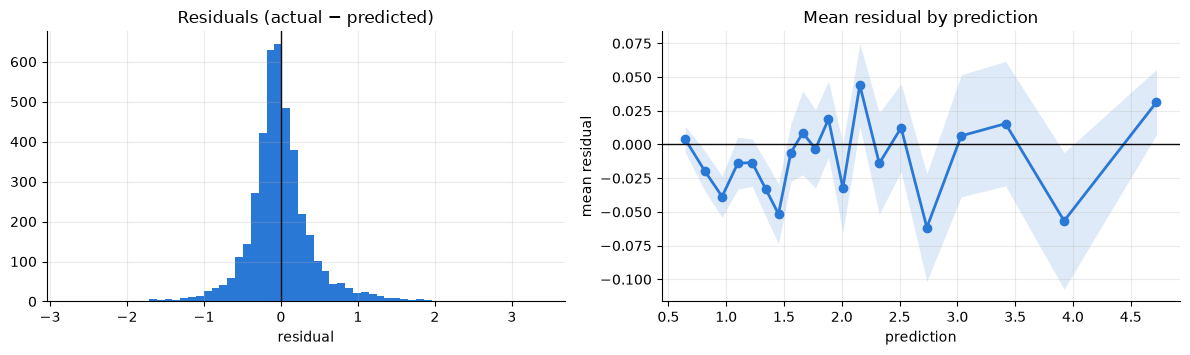

In [12]:
def plot_residuals(y_true, y_pred, x=None, x_name="prediction", bins=20, title=""):
    # Left: residual histogram. Right: mean residual (±1 se) across bins of x (default: the prediction).
    # A flat line at 0 on the right = no systematic bias.
    res = np.asarray(y_true) - np.asarray(y_pred)
    x = np.asarray(y_pred if x is None else x)
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    axes[0].hist(res, bins=60, color=PALETTE[0]); axes[0].axvline(0, color="#0b0b0b", lw=1)
    axes[0].set(title="Residuals (actual − predicted)", xlabel="residual")
    b = pd.qcut(x, bins, duplicates="drop")
    g = pd.Series(res).groupby(b, observed=True).agg(["mean", "std", "count"])
    mid = pd.Series(x).groupby(b, observed=True).mean()
    se = g["std"] / np.sqrt(g["count"])
    axes[1].plot(mid, g["mean"], "o-", color=PALETTE[0], ms=6)
    axes[1].fill_between(mid, g["mean"] - se, g["mean"] + se, color=PALETTE[0], alpha=0.15, lw=0)
    axes[1].axhline(0, color="#0b0b0b", lw=1); axes[1].set(title=f"Mean residual by {x_name}", xlabel=x_name, ylabel="mean residual")
    fig.suptitle(title); fig.tight_layout()
    return fig

plot_residuals(yh_te, pred_h);
plt.show()

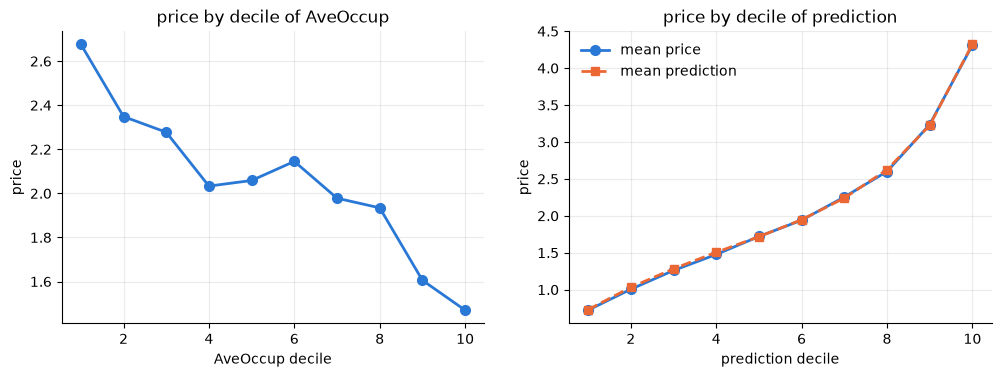

In [13]:
def plot_deciles(x, y, q=10, x_name="x", y_name="y", ax=None, pred=None):
    # Mean of y in each decile of x (optionally also the mean prediction). The single most useful
    # "is there a signal, and is it linear?" plot for a feature or for a model's output.
    ax = ax or plt.subplots()[1]
    d = pd.DataFrame({"x": np.asarray(x), "y": np.asarray(y)})
    if pred is not None: d["pred"] = np.asarray(pred)
    d["bin"] = pd.qcut(d["x"].rank(method="first"), q, labels=False) + 1
    g = d.groupby("bin").mean()
    ax.plot(g.index, g["y"], "o-", color=PALETTE[0], ms=7, label=f"mean {y_name}")
    if pred is not None: ax.plot(g.index, g["pred"], "s--", color=PALETTE[1], ms=6, label="mean prediction"); ax.legend()
    ax.set(xlabel=f"{x_name} decile", ylabel=y_name, title=f"{y_name} by decile of {x_name}")
    return ax

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_deciles(Xh_te["AveOccup"], yh_te, x_name="AveOccup", y_name="price", ax=axes[0])
plot_deciles(pred_h, yh_te, x_name="prediction", y_name="price", pred=pred_h, ax=axes[1]);
plt.show()

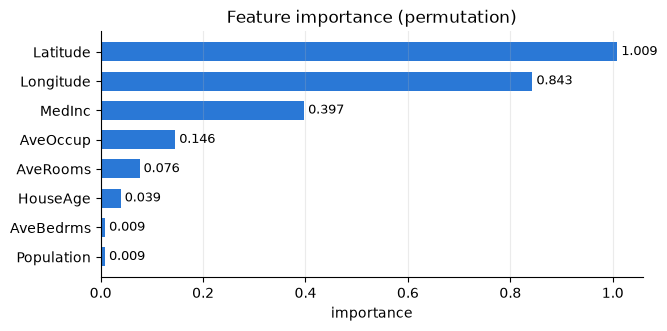

In [14]:
def plot_importance(model=None, X=None, y=None, importances=None, top=15, method="permutation", title=""):
    # Feature importance bar chart. method="permutation" (needs held-out X, y; recommended) or "builtin".
    if importances is None:
        if method == "permutation":
            from sklearn.inspection import permutation_importance
            r = permutation_importance(model, X, y, n_repeats=5, random_state=0, n_jobs=1)
            importances = pd.Series(r.importances_mean, index=X.columns)
        else:
            importances = pd.Series(model.feature_importances_, index=X.columns)
    s = importances.sort_values().tail(top)
    return plot_bar(s, title=title or f"Feature importance ({method})", xlabel="importance", fmt="{:.3f}")

plot_importance(reg, Xh_te, yh_te);

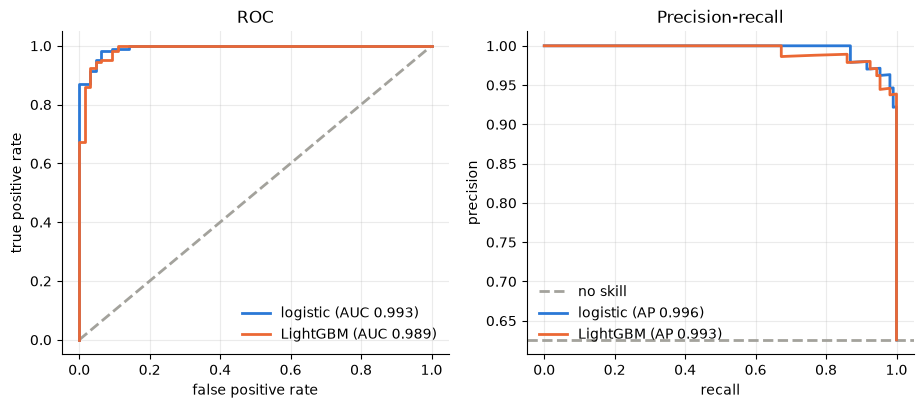

In [15]:
def plot_roc_pr(y_true, proba, label="model", axes=None):
    # ROC and precision-recall curves side by side; call repeatedly with the same axes to compare models.
    from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
    if axes is None:
        _, axes = plt.subplots(1, 2, figsize=(11, 4.2))
        axes[0].plot([0, 1], [0, 1], color=GREY, ls="--")
        axes[1].axhline(np.mean(y_true), color=GREY, ls="--", label="no skill")
    k = len([l for l in axes[0].get_lines() if l.get_label() and not l.get_label().startswith("_")])
    fpr, tpr, _ = roc_curve(y_true, proba); prec, rec, _ = precision_recall_curve(y_true, proba)
    axes[0].plot(fpr, tpr, color=PALETTE[k], label=f"{label} (AUC {roc_auc_score(y_true, proba):.3f})")
    axes[1].plot(rec, prec, color=PALETTE[k], label=f"{label} (AP {average_precision_score(y_true, proba):.3f})")
    axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC"); axes[0].legend(loc="lower right")
    axes[1].set(xlabel="recall", ylabel="precision", title="Precision-recall"); axes[1].legend(loc="lower left")
    return axes

axes = plot_roc_pr(yc_te, proba_c, "logistic")
rf_proba = lgb.LGBMClassifier(n_estimators=200, verbose=-1).fit(Xc_tr, yc_tr).predict_proba(Xc_te)[:, 1]
plot_roc_pr(yc_te, rf_proba, "LightGBM", axes=axes);
plt.show()

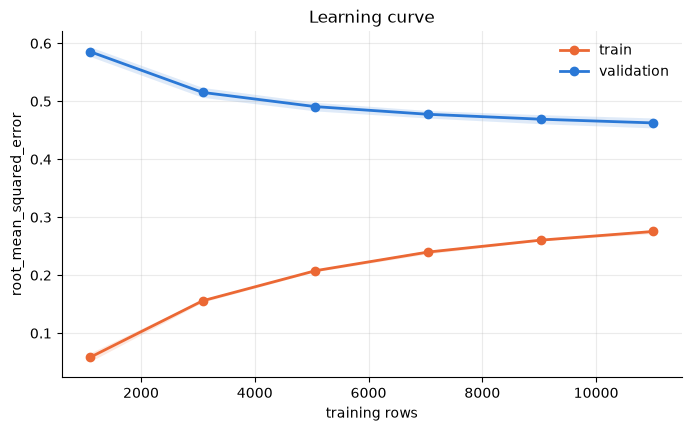

In [16]:
def plot_learning_curve(model, X, y, cv=5, scoring="neg_root_mean_squared_error", sizes=np.linspace(0.1, 1, 6), ax=None):
    # Train vs validation score as the training set grows. Big gap = variance (more data/regularise helps);
    # both bad and close = bias (need a better model/features).
    from sklearn.model_selection import learning_curve
    n, tr, va = learning_curve(model, X, y, cv=cv, scoring=scoring, train_sizes=sizes, n_jobs=1)
    sign = -1 if scoring.startswith("neg_") else 1
    ax = ax or plt.subplots()[1]
    for scores, name, c in [(tr, "train", PALETTE[1]), (va, "validation", PALETTE[0])]:
        m, s = sign * scores.mean(1), scores.std(1)
        ax.plot(n, m, "o-", color=c, label=name, ms=6); ax.fill_between(n, m - s, m + s, color=c, alpha=0.15, lw=0)
    ax.set(xlabel="training rows", ylabel=scoring.replace("neg_", ""), title="Learning curve"); ax.legend()
    return ax

plot_learning_curve(lgb.LGBMRegressor(n_estimators=300, verbose=-1), Xh_tr, yh_tr, cv=3);
plt.show()

In [17]:
def plot_cv_comparison(results, metric_col="mean", sd_col="sd", title="CV comparison (lower is better)", ax=None):
    # Horizontal bars with ±1 sd error bars from a DataFrame indexed by model name (e.g. compare_models() output).
    r = results.sort_values(metric_col, ascending=False)
    ax = ax or plt.subplots(figsize=(7.5, 0.5 * len(r) + 1.2))[1]
    ax.barh(r.index, r[metric_col], xerr=r[sd_col], color=PALETTE[0], height=0.6, error_kw=dict(ecolor="#52514e", lw=1))
    for i, (v, e) in enumerate(zip(r[metric_col], r[sd_col])): ax.text(v + e, i, f"  {v:.3f}", va="center", fontsize=9)
    ax.set_xlim(0, (r[metric_col] + r[sd_col]).max() * 1.15)
    ax.set(title=title, xlabel=metric_col); ax.grid(axis="y", visible=False)
    return ax
# Demo after compare_models() in section 4.
plt.show()

## 3. Time series

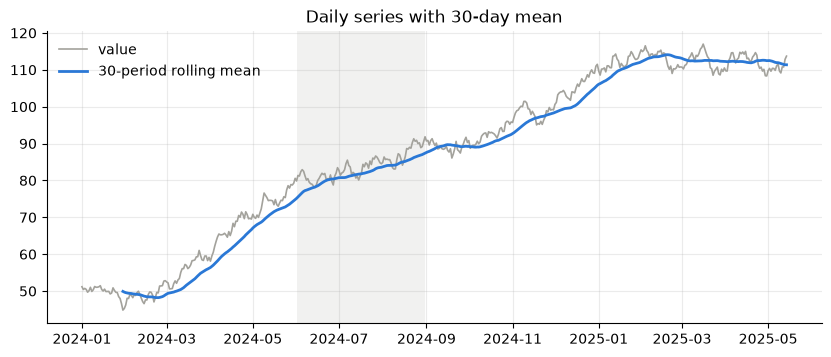

In [18]:
def plot_series(s, rolling=None, title="", ylabel="", ax=None, shade=None):
    # Time series with an optional trailing rolling mean and shaded periods (list of (start, end) tuples).
    ax = ax or plt.subplots(figsize=(10, 3.8))[1]
    ax.plot(s.index, s.values, color=PALETTE[0] if rolling is None else GREY, lw=1.2 if rolling else 2, label=s.name or "series")
    if rolling:
        ax.plot(s.index, s.rolling(rolling).mean(), color=PALETTE[0], label=f"{rolling}-period rolling mean")
        ax.legend()
    for start, end in (shade or []):
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=GREY, alpha=0.15, lw=0)
    ax.set(title=title, ylabel=ylabel)
    return ax

ts = pd.Series(np.cumsum(rng.normal(0.1, 1, 500)) + 50, index=pd.date_range("2024-01-01", periods=500, freq="D"), name="value")
plot_series(ts, rolling=30, title="Daily series with 30-day mean", shade=[("2024-06-01", "2024-08-31")]);
plt.show()

## 4. Everyday helpers

In [19]:
import time, os, random
from contextlib import contextmanager

@contextmanager
def timer(name="block"):
    # with timer("fit"): model.fit(X, y)
    t = time.perf_counter(); yield; print(f"[{name}] {time.perf_counter() - t:.2f}s")

def seed_everything(seed=42):
    # Make numpy / random / hashing reproducible (pass random_state=seed to models too).
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)

def split_3way(X, y, val=0.2, test=0.2, stratify=False, seed=42):
    # Train / validation / test split in one call. Returns X_tr, X_va, X_te, y_tr, y_va, y_te.
    strat = y if stratify else None
    X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=test, stratify=strat, random_state=seed)
    strat = y_tmp if stratify else None
    X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=val / (1 - test), stratify=strat, random_state=seed)
    return X_tr, X_va, X_te, y_tr, y_va, y_te

with timer("split"):
    parts = split_3way(Xh, yh)
print([len(p) for p in parts[:3]])

[split] 0.01s
[12384, 4128, 4128]


In [20]:
from sklearn import metrics as skm

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return pd.Series({
        "RMSE": skm.root_mean_squared_error(y_true, y_pred), "MAE": skm.mean_absolute_error(y_true, y_pred),
        "R2": skm.r2_score(y_true, y_pred), "R2_vs_zero": 1 - np.mean((y_true - y_pred) ** 2) / np.mean(y_true ** 2),
        "corr": np.corrcoef(y_true, y_pred)[0, 1], "slope_actual_on_pred": np.cov(y_pred, y_true)[0, 1] / np.var(y_pred, ddof=1),
    })

def classification_metrics(y_true, proba, threshold=0.5):
    pred = (np.asarray(proba) >= threshold).astype(int)
    return pd.Series({
        "AUC": skm.roc_auc_score(y_true, proba), "PR_AUC": skm.average_precision_score(y_true, proba),
        "log_loss": skm.log_loss(y_true, proba), "brier": skm.brier_score_loss(y_true, proba),
        "accuracy": skm.accuracy_score(y_true, pred), "precision": skm.precision_score(y_true, pred, zero_division=0),
        "recall": skm.recall_score(y_true, pred), "F1": skm.f1_score(y_true, pred),
    })

pd.concat({"LightGBM (house)": regression_metrics(yh_te, pred_h)}, axis=1).round(4)

,LightGBM (house)
RMSE,0.4388
MAE,0.2926
R2,0.8523
R2_vs_zero,0.9651
corr,0.9233
slope_actual_on_pred,1.0039


In [21]:
classification_metrics(yc_te, proba_c).round(4).to_frame("logistic (cancer)")

,logistic (cancer)
AUC,0.9928
PR_AUC,0.9957
log_loss,0.1173
brier,0.0330
accuracy,0.9591
precision,0.9545
recall,0.9813
F1,0.9677


,mean,sd,fit_s
LightGBM,0.4684,0.0064,0.3609
Ridge,0.7269,0.0199,0.0144
mean baseline,1.1569,0.0103,0.0020


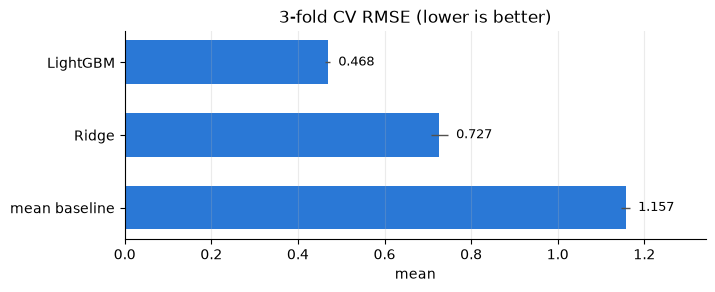

In [22]:
from sklearn.model_selection import KFold, cross_validate

def compare_models(models, X, y, cv=None, scoring="neg_root_mean_squared_error", groups=None):
    # Cross-validate a dict {name: estimator} on the SAME folds; returns mean, sd and fit time per model.
    cv = cv or KFold(5, shuffle=True, random_state=42)
    rows = {}
    for name, m in models.items():
        r = cross_validate(m, X, y, cv=cv, scoring=scoring, groups=groups)
        s = -r["test_score"] if scoring.startswith("neg_") else r["test_score"]
        rows[name] = {"mean": s.mean(), "sd": s.std(), "fit_s": r["fit_time"].mean()}
    return pd.DataFrame(rows).T.sort_values("mean", ascending=scoring.startswith("neg_"))   # best first

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV
results = compare_models({
    "mean baseline": DummyRegressor(),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV()),
    "LightGBM": lgb.LGBMRegressor(n_estimators=300, verbose=-1),
}, Xh_tr, yh_tr, cv=KFold(3, shuffle=True, random_state=0))
display(results.round(4))
plot_cv_comparison(results, title="3-fold CV RMSE (lower is better)");

In [23]:
import joblib
from pathlib import Path

def save_model(model, path):
    # Save any sklearn-compatible model (incl. pipelines, LightGBM/XGBoost/CatBoost sklearn wrappers).
    Path(path).parent.mkdir(parents=True, exist_ok=True); joblib.dump(model, path)

def load_model(path):
    return joblib.load(path)

def savefig(fig_or_ax, name, folder="figures"):
    # Save the current figure as PNG for slides/reports.
    fig = getattr(fig_or_ax, "figure", fig_or_ax)
    Path(folder).mkdir(exist_ok=True); fig.savefig(Path(folder) / f"{name}.png")

# Example (commented out so running the notebook doesn't write files):
# save_model(reg, "models/lgbm_house.joblib"); reg2 = load_model("models/lgbm_house.joblib")
# ax = plot_pred_vs_actual(yh_te, pred_h); savefig(ax, "pred_vs_actual")

## Quick pandas/seaborn alternatives

For a fast look during exploration, pandas plots are one-liners (they use the same style once `set_style()` is called):

```python
df["col"].hist(bins=50)
df.plot.scatter(x="a", y="b", alpha=0.3)
df.groupby("g")["y"].mean().sort_values().plot.barh()
df.set_index("date")["y"].plot()
df.boxplot(column="y", by="g")
pd.plotting.scatter_matrix(df[cols], figsize=(10, 10))
```

seaborn (`pip install seaborn`) adds higher-level plots: `sns.histplot`, `sns.boxplot`, `sns.regplot`, `sns.heatmap`, `sns.pairplot`.
Use the functions above when the chart goes into a presentation.